# Task 4 · Two hybrids
**CNN + attention.** The three conv layers of the Task 1 CNN (without the last pooling) give an 8×8 grid of 128-d
features. With a learned CLS token and position embeddings, one multi-head self-attention layer lets the CLS token
weigh all 64 locations by content, and an MLP classifies it.

**DINOv2 + MLP.** A frozen, self-supervised DINOv2-small (ViT-S/14, 22M parameters, never trained on CIFAR labels)
embeds each image once, upsampled to 112×112; a small MLP learns the classes from the 384-d embeddings.

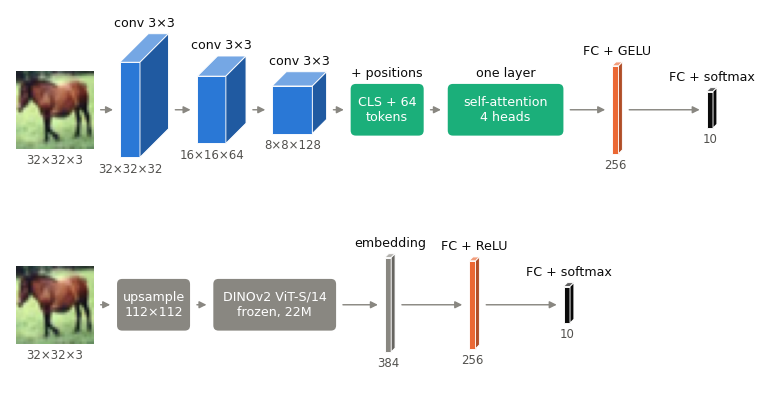

In [1]:
from hw3 import *
from sklearn.manifold import TSNE

B = json.load(open(BEST))
X, Y, Xte, Yte = cifar()
diagram('arch_hybrids', [cnn_layers(B['cnn']['arch'])[:3] + [('CLS + 64\ntokens', '+ positions', COL['attn']),
                                                            ('self-attention\n4 heads', 'one layer', COL['attn']),
                                                            (256, 'FC + GELU', COL['mlp']), (10, 'FC + softmax', INK)],
                         [('upsample\n112×112', '', MUTED), ('DINOv2 ViT-S/14\nfrozen, 22M', '', MUTED),
                          (384, 'embedding', MUTED), (256, 'FC + ReLU', COL['mlp']), (10, 'FC + softmax', INK)]],
        X[int((Y == 7).nonzero()[0])])

In [2]:
if not os.path.exists(DINO):
    from transformers import Dinov2Model
    vit = Dinov2Model.from_pretrained('facebook/dinov2-small').eval()
    m, s = torch.tensor([.485, .456, .406]).view(1, 3, 1, 1), torch.tensor([.229, .224, .225]).view(1, 3, 1, 1)
    embed = lambda X: torch.cat([vit(pixel_values=(F.interpolate(x / 255, 112, mode='bicubic') - m) / s).pooler_output
                                 for x in X.split(250)])
    t = time.perf_counter()
    with torch.inference_mode():
        Z = dict(train=embed(X), test=embed(Xte))
    torch.save(Z | dict(seconds=time.perf_counter() - t), DINO)
Z = torch.load(DINO)
Z['train'].shape, Z['seconds'] / 60

(torch.Size([50000, 384]), 26.22633841833255)

In [3]:
S = {B['mlp']['key']: dict(model=partial(MLP, B['mlp']['arch']), lr=B['mlp']['lr']),
     B['cnn']['key']: dict(model=partial(CNN, B['cnn']['arch']), lr=B['cnn']['lr']),
     'attn': dict(model=partial(AttnCNN, B['cnn']['arch']), lr=B['cnn']['lr']),
     'dino_mlp': dict(model=partial(MLP, (256,), .2, 384), lr=1e-3, epochs=20, kind='dino')}
G = dict(zip(['MLP', 'CNN', 'CNN + attention', 'DINOv2 + MLP'], zip(S, [COL[c] for c in ('mlp', 'cnn', 'attn', 'dino')])))
R = cv(S)
P = pd.DataFrame({k: profile(S[k]['model'], S[k].get('kind', 'pixels')) for k in S}).T
P['val'], P['test'] = ([ms(last(R[k], m)) for k in S] for m in ('val_acc', 'test_acc'))
P.set_axis(list(G))

,params,mflops,weights,adam,acts,epoch,val,test
MLP,3805450.0,7.607296,14.516640,43.549919,2.375000,12.550531,56.7 (0.4),56.4 (0.3)
CNN,620810.0,21.697536,2.368202,7.104607,78.628418,32.514062,81.4 (0.2),81.0 (0.3)
CNN + attention,204298.0,25.039872,0.779335,2.338005,92.507324,41.353375,79.7 (0.4),79.8 (0.2)
DINOv2 + MLP,101130.0,0.201728,0.385780,1.157341,0.562500,0.677812,90.5 (0.4),90.1 (0.1)


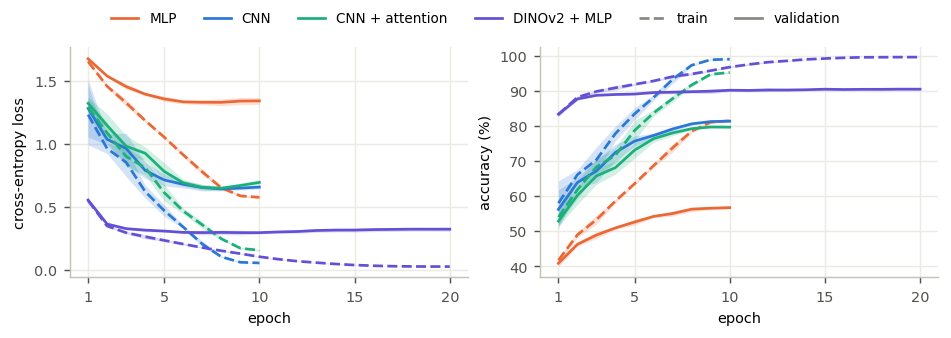

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
curves({k: (R[n], c) for k, (n, c) in G.items()}, axes)
for ax in axes:
    ax.set_xticks([1, 5, 10, 15, 20])
save(fig, 'hybrid_curves')

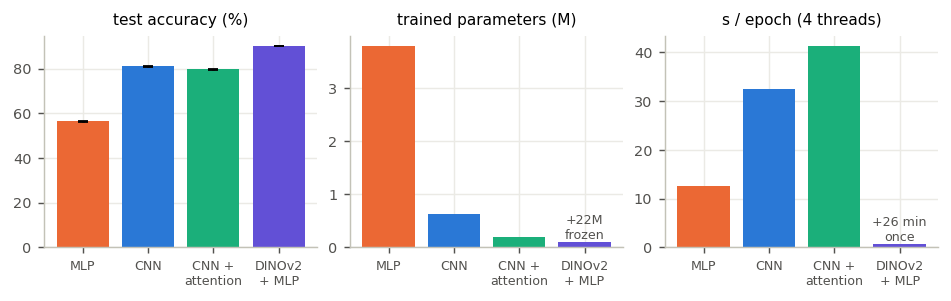

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2))
names, colors = ['MLP', 'CNN', 'CNN +\nattention', 'DINOv2\n+ MLP'], [c for _, c in G.values()]
acc = np.array([last(R[n], 'test_acc') for n in S]) * 100
axes[0].bar(names, acc.mean(1), yerr=acc.std(1, ddof=1), capsize=3, color=colors)
axes[1].bar(names, P.params / 1e6, color=colors)
axes[1].text(3, P.params.iloc[3] / 1e6, '+22M\nfrozen', ha='center', va='bottom', fontsize=7, color=TEXT)
axes[2].bar(names, P.epoch, color=colors)
axes[2].text(3, P.epoch.iloc[3], f"+{Z['seconds'] / 60:.0f} min\nonce", ha='center', va='bottom', fontsize=7, color=TEXT)
for ax, t in zip(axes, ('test accuracy (%)', 'trained parameters (M)', 's / epoch (4 threads)')):
    ax.set_title(t)
    ax.tick_params(axis='x', labelsize=7)
save(fig, 'hybrid_compare')

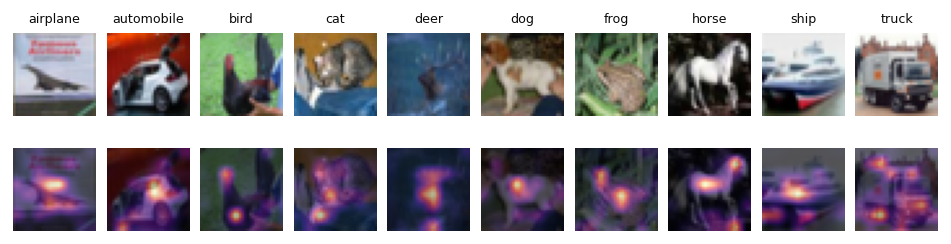

In [6]:
net = load('attn', S['attn']['model'])
idx = torch.tensor([int((Yte == c).nonzero()[0]) for c in range(10)])
with torch.no_grad():
    out, a = net(prep(Xte[idx]), maps=True)
a = F.interpolate(a.view(-1, 1, 8, 8), size=32, mode='bilinear')[:, 0]
fig, axes = plt.subplots(2, 10, figsize=(7.2, 1.85))
for j, k in enumerate(idx):
    for ax in axes[:, j]:
        ax.imshow(Xte[k].permute(1, 2, 0))
        ax.axis('off')
    axes[1, j].imshow(a[j], cmap='magma', alpha=.65)
    axes[0, j].set_title(CLASSES[out[j].argmax()], fontsize=7, color=INK if out[j].argmax() == Yte[k] else RED)
save(fig, 'attention')

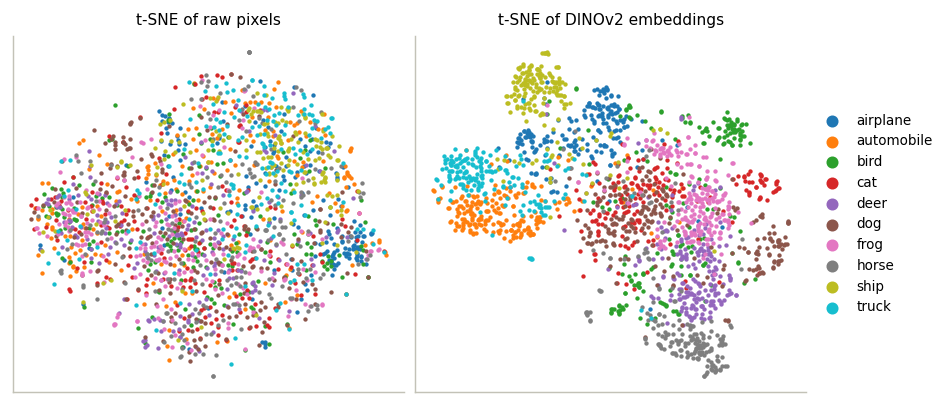

In [7]:
sub = torch.randperm(len(Yte), generator=torch.Generator().manual_seed(SEED))[:2000]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3))
for ax, (t, e) in zip(axes, {'raw pixels': prep(Xte[sub]).flatten(1), 'DINOv2 embeddings': Z['test'][sub]}.items()):
    p = TSNE(2, init='pca', random_state=SEED).fit_transform(e.numpy())
    for c in range(10):
        ax.scatter(*p[(Yte[sub] == c).numpy()].T, s=2, color=plt.cm.tab10(c), label=CLASSES[c])
    ax.set(title=f't-SNE of {t}', xticks=[], yticks=[])
axes[1].legend(markerscale=4, loc='center left', bbox_to_anchor=(1, .5))
save(fig, 'tsne')

In [8]:
tex('t4', dinoMinutes=f"{Z['seconds'] / 60:.0f}", attnSlow=f"{P.epoch['attn'] / P.epoch[B['cnn']['key']]:.1f}",
    attnDiff=pdiff(R['attn'], R[B['cnn']['key']]),
    dinoDiff=pdiff(R['dino_mlp'], R[B['cnn']['key']]), **{p + m: v for p, n in (('attn', 'attn'), ('dino', 'dino_mlp')) for m, v in (
    ('Test', P.test[n]), ('Val', P.val[n]), ('Params', f'{P.params[n] / 1e3:.0f}'), ('Epoch', f'{P.epoch[n]:.1f}'))})